# Thinking Trace Semantic Crossover

In [65]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [66]:
import sys, pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pingouin as pg
from scipy import stats

ANALYSIS = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ANALYSIS))

from helpers import util as U

## Load Precomputed Trace Cosines

`d1_mean` is the target-axis cosine. `d2_mean` is the salience-axis cosine.

In [67]:
trace_cosines = pd.read_json(ANALYSIS / "data" / "cosines_pooled.jsonl", lines=True)
trace_cosines.head()

,arm,task,name,d1_mean,d1_n,d2_mean,d2_n
0,search,bottle,000000005600.jpg,0.187407,504,0.148034,504
1,search,bottle,000000025986.jpg,0.139913,735,0.104696,735
2,search,bottle,000000039659.jpg,0.216467,334,0.147207,334
3,search,bottle,000000076518.jpg,0.203246,301,0.153002,301
4,search,bottle,000000085556.jpg,0.137838,755,0.163084,755


In [68]:
trace_cosines.groupby("arm").agg(
    n_images=("name", "size"),
    target_axis_sentences=("d1_n", "sum"),
    salience_axis_sentences=("d2_n", "sum"),
).reset_index()

,arm,n_images,target_axis_sentences,salience_axis_sentences
0,memory,2416,1456709,1456709
1,search,2416,1499532,1499532


## Pair Search and Memory Arms

In [69]:
trace_pairs = U.paired_trace_cosines(trace_cosines)
trace_pairs.head()

,task,name,d1_mean_memory,d1_mean_search,d2_mean_memory,d2_mean_search
0,bottle,000000000196.jpg,0.096624,0.081168,0.180581,0.142643
1,bottle,000000003992.jpg,0.174394,0.114894,0.175438,0.129774
2,bottle,000000005522.jpg,0.134580,0.130390,0.211840,0.151569
3,bottle,000000005600.jpg,0.144252,0.187407,0.202930,0.148034
4,bottle,000000009866.jpg,0.166896,0.206530,0.200349,0.151574


In [70]:
trace_long = trace_pairs.melt(
    id_vars=["task", "name"],
    value_vars=[
        "d1_mean_search",
        "d1_mean_memory",
        "d2_mean_search",
        "d2_mean_memory",
    ],
    var_name="cell",
    value_name="cosine",
)

trace_long["semantic_axis"] = trace_long["cell"].map(
    {
        "d1_mean_search": "target",
        "d1_mean_memory": "target",
        "d2_mean_search": "salience",
        "d2_mean_memory": "salience",
    }
)
trace_long["trace_arm"] = trace_long["cell"].map(
    {
        "d1_mean_search": "search",
        "d1_mean_memory": "memory",
        "d2_mean_search": "search",
        "d2_mean_memory": "memory",
    }
)

trace_long.head()

,task,name,cell,cosine,semantic_axis,trace_arm
0,bottle,000000000196.jpg,d1_mean_search,0.081168,target,search
1,bottle,000000003992.jpg,d1_mean_search,0.114894,target,search
2,bottle,000000005522.jpg,d1_mean_search,0.130390,target,search
3,bottle,000000005600.jpg,d1_mean_search,0.187407,target,search
4,bottle,000000009866.jpg,d1_mean_search,0.206530,target,search


## Semantic Summary

In [71]:
trace_means = (
    trace_long
    .groupby(["semantic_axis", "trace_arm"], sort=False)["cosine"]
    .agg(["mean", "std", "count"])
    .reset_index()
)

trace_means

,semantic_axis,trace_arm,mean,std,count
0,target,search,0.199100,0.060010,2416
1,target,memory,0.164331,0.042333,2416
2,salience,search,0.132487,0.022680,2416
3,salience,memory,0.188837,0.017291,2416


## Repeated-Measures ANOVA

The semantic crossover is tested as a 2x2 within-image design: trace arm (`search`, `memory`) by semantic axis (`target`, `salience`).

In [72]:
trace_anova_data = trace_long.copy()
trace_anova_data["picture"] = trace_anova_data["task"] + " / " + trace_anova_data["name"]

trace_rmanova = pg.rm_anova(
    data=trace_anova_data,
    dv="cosine",
    within=["trace_arm", "semantic_axis"],
    subject="picture",
    detailed=True,
)

trace_rmanova

,Source,SS,ddof1,ddof2,MS,F,p_unc,p_GG_corr,ng2,eps
0,trace_arm,0.281298,1,2415,0.281298,532.807406,1.079843e-106,1.079843e-106,0.018421,1.0
1,semantic_axis,1.070867,1,2415,1.070867,383.729576,2.031841e-79,2.031841e-79,0.066680,1.0
2,trace_arm * semantic_axis,5.014833,1,2415,5.014833,7175.842361,0.000000e+00,0.000000e+00,0.250693,1.0


In [73]:
pairwise_results = []

for semantic_axis, axis_data in trace_anova_data.groupby("semantic_axis", sort=False):
    paired_arms = (
        axis_data
        .pivot(index="picture", columns="trace_arm", values="cosine")
        .dropna(subset=["search", "memory"])
    )
    difference = paired_arms["search"] - paired_arms["memory"]
    test = pg.ttest(paired_arms["search"], paired_arms["memory"], paired=True)
    ci_margin = stats.t.ppf(0.975, len(difference) - 1) * difference.std(ddof=1) / np.sqrt(len(difference)) # using stats since pingouin's ci95 retunrs 2 decimals
    ci_low = difference.mean() - ci_margin
    ci_high = difference.mean() + ci_margin
    pairwise_results.append(
        {
            "semantic_axis": semantic_axis,
            "A": "search",
            "B": "memory",
            "T": test["T"].iloc[0],
            "dof": test["dof"].iloc[0],
            "alternative": test["alternative"].iloc[0],
            "p_unc": test["p_val"].iloc[0],
            "cohen": test["cohen_d"].iloc[0],
            "ci95_low": f"{ci_low:.3f}",
            "ci95_high": f"{ci_high:.3f}",
        }
    )

trace_pairwise_tests = pd.DataFrame(pairwise_results)
trace_pairwise_tests[
    ["semantic_axis", "A", "B", "T", "dof", "alternative", "p_unc", "cohen", "ci95_low", "ci95_high"]
]

,semantic_axis,A,B,T,dof,alternative,p_unc,cohen,ci95_low,ci95_high
0,target,search,memory,38.386963,2415,two-sided,4.202029e-252,0.669551,0.033,0.037
1,salience,search,memory,-127.551310,2415,two-sided,0.000000e+00,2.794282,-0.057,-0.055


In [74]:
pg.ttest(paired_arms["search"], paired_arms["memory"], paired=True)

,T,dof,alternative,p_val,CI95,cohen_d,power,BF10
T_test,-127.55131,2415,two-sided,0.0,"[-0.06, -0.06]",2.794282,1.0,inf


## Split Violin Plot

This mirrors the split violin style used in the output-crossover notebook, with one distribution per semantic axis and trace arm.

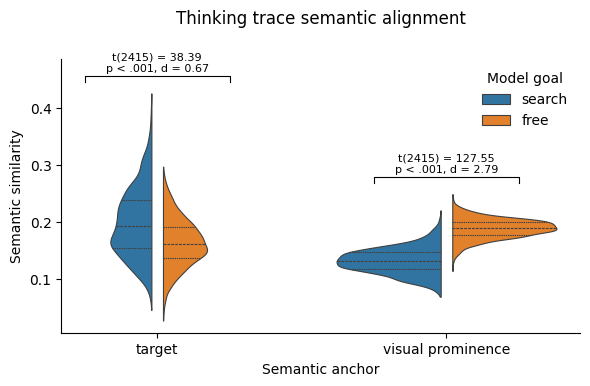

In [75]:
plot_data = trace_long.copy()
semantic_axis_order = ["target", "salience"]
trace_arm_order = ["search", "memory"]
plot_data["semantic_axis"] = pd.Categorical(
    plot_data["semantic_axis"],
    categories=semantic_axis_order,
    ordered=True,
)
plot_data["trace_arm"] = pd.Categorical(
    plot_data["trace_arm"],
    categories=trace_arm_order,
    ordered=True,
)

fig, ax = plt.subplots(figsize=(6, 4))
x_positions = np.arange(len(semantic_axis_order))

sns.violinplot(
    data=plot_data,
    x="semantic_axis",
    y="cosine",
    hue="trace_arm",
    order=semantic_axis_order,
    hue_order=trace_arm_order,
    split=True,
    gap=0.1,
    inner="quartile",
    cut=0,
    linewidth=0.8,
    ax=ax,
)

annotation_top = plot_data["cosine"].max()
annotation_step = 0.03

for axis_index, semantic_axis in enumerate(semantic_axis_order):
    pairwise_row = trace_pairwise_tests[
        trace_pairwise_tests["semantic_axis"] == semantic_axis
    ].iloc[0]

    x_left = x_positions[axis_index] - 0.25
    x_right = x_positions[axis_index] + 0.25
    y_base = plot_data.loc[
        plot_data["semantic_axis"] == semantic_axis,
        "cosine",
    ].max() + 0.02
    y_top = y_base + 0.01

    t_display = abs(pairwise_row["T"])
    d_display = abs(pairwise_row["cohen"])
    annotation = (
        f"t({pairwise_row['dof']:.0f}) = {t_display:.2f}\n"
        f"{U.format_p_value(pairwise_row['p_unc'])}, d = {d_display:.2f}"
    )

    ax.plot(
        [x_left, x_left, x_right, x_right],
        [y_base, y_top, y_top, y_base],
        color="black",
        linewidth=0.8,
    )
    ax.text(
        (x_left + x_right) / 2,
        y_top + 0.005,
        annotation,
        ha="center",
        va="bottom",
        fontsize=8,
    )
    annotation_top = max(annotation_top, y_top + annotation_step)

ax.set_xticks(x_positions)
ax.set_xticklabels(["target", "visual prominence"])
ax.set_xlabel("Semantic anchor")
ax.set_ylabel("Semantic similarity")
ax.set_title("Thinking trace semantic alignment", y=1.1)
ax.set_ylim(top=annotation_top)
handles, _ = ax.get_legend_handles_labels()
ax.legend(handles, ["search", "free"], title="Model goal", frameon=False)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()

## Per-Category Effects

In [76]:
axis_specs = [
    ("target", "d1_mean", "D1 target anchor"),
    ("salience", "d2_mean", "D2 prominence anchor"),
]

category_rows = []

for task, task_cosines in trace_cosines.groupby("task", sort=True):
    task_pairs = U.paired_trace_cosines(task_cosines)
    if len(task_pairs) < 3:
        continue

    for semantic_axis, column, label in axis_specs:
        search = task_pairs[f"{column}_search"].to_numpy(float)
        memory = task_pairs[f"{column}_memory"].to_numpy(float)
        difference = search - memory
        category_rows.append(
            {
                "metric": label,
                "task": task,
                "n": len(difference),
                "search_mean": search.mean(),
                "memory_mean": memory.mean(),
                "delta": difference.mean(),
                "cohens_d": pg.compute_effsize(search, memory, paired=True, eftype="cohen"),
            }
        )

trace_by_category = pd.DataFrame(category_rows)
trace_by_category.head()

,metric,task,n,search_mean,memory_mean,delta,cohens_d
0,D1 target anchor,bottle,130,0.165690,0.139745,0.025945,0.590210
1,D2 prominence anchor,bottle,130,0.148677,0.190373,-0.041697,-2.155968
2,D1 target anchor,bowl,110,0.188975,0.186960,0.002015,0.061626
3,D2 prominence anchor,bowl,110,0.143233,0.191241,-0.048008,-2.522245
4,D1 target anchor,car,79,0.228946,0.180316,0.048630,1.010707


In [77]:
category_wide = trace_by_category.pivot_table(
    index="task",
    columns="metric",
    values="cohens_d",
    aggfunc="first",
).reset_index()
category_wide["target_anchor_positive"] = category_wide["D1 target anchor"] > 0
category_wide["prominence_anchor_negative"] = category_wide["D2 prominence anchor"] < 0
category_wide["full_dissociation"] = (
    category_wide["target_anchor_positive"]
    & category_wide["prominence_anchor_negative"]
)

print("Target categories:", len(category_wide))
print("Full dissociation categories:", category_wide["full_dissociation"].sum())
category_wide

Target categories: 18
Full dissociation categories: 18


metric,task,D1 target anchor,D2 prominence anchor,target_anchor_positive,prominence_anchor_negative,full_dissociation
0,bottle,0.590210,-2.155968,True,True,True
1,bowl,0.061626,-2.522245,True,True,True
2,car,1.010707,-3.973709,True,True,True
3,chair,1.317576,-2.571651,True,True,True
4,clock,0.157135,-3.698266,True,True,True
5,cup,0.654419,-2.442995,True,True,True
6,fork,0.743825,-3.029138,True,True,True
7,keyboard,1.344974,-3.726484,True,True,True
8,knife,1.015867,-2.571358,True,True,True
9,laptop,0.676009,-2.921109,True,True,True


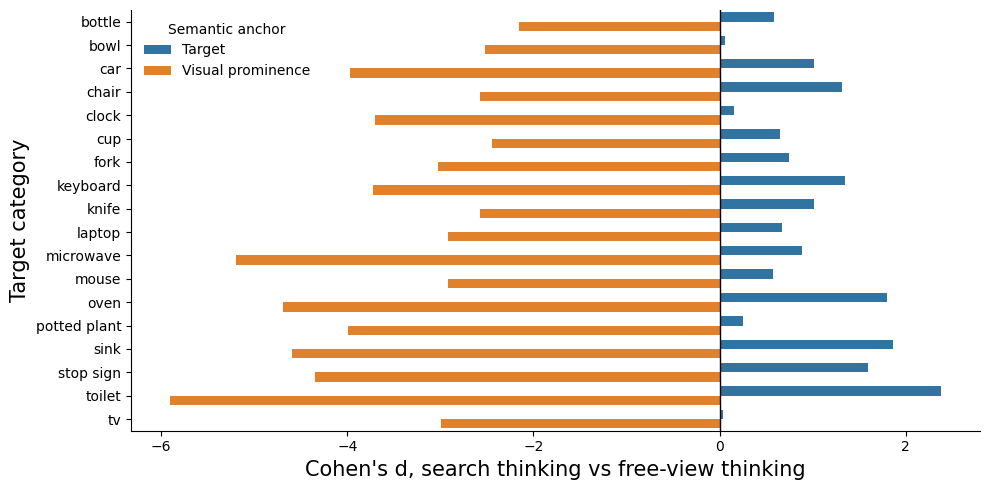

In [84]:
fig, ax = plt.subplots(figsize=(10, 5))
category_plot = trace_by_category.copy()
category_plot["metric"] = category_plot["metric"].replace(
    {
        "D1 target anchor": "Target",
        "D2 prominence anchor": "Visual prominence",
    }
)

sns.barplot(
    data=category_plot,
    x="cohens_d",
    y="task",
    hue="metric",
    hue_order=["Target", "Visual prominence"],
    orient="h",
    ax=ax,
)
ax.axvline(0, color="black", linewidth=1)
ax.set_xlabel("Cohen's d, search thinking vs free-view thinking", fontsize=15)
ax.set_ylabel("Target category", fontsize=15)
ax.legend(title="Semantic anchor", frameon=False, loc="best")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()